PART 1: LSTM MACHINE TRANSLATION
English Vocabulary: 35
Hindi Vocabulary: 39

Training LSTM Translation Model...
Translation Model Trained Successfully!

English Sentence: this is a book
Hindi Translation: यह एक किताब है

PART 2: LSTM HANDWRITING RECOGNITION
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST Dataset Loaded Successfully!
Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)

Handwriting Recognition Model:


Model: "LSTM_Handwriting_Recognition"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,290 (348.79 KB)

 Trainable params: 89,290 (348.79 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM Handwriting Model...
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - accuracy: 0.7871 - loss: 0.6610 - val_accuracy: 0.9418 - val_loss: 0.1853
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - accuracy: 0.9436 - loss: 0.2027 - val_accuracy: 0.9637 - val_loss: 0.1161
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 49ms/step - accuracy: 0.9604 - loss: 0.1379 - val_accuracy: 0.9762 - val_loss: 0.0852
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - accuracy: 0.9701 - loss: 0.1065 - val_accuracy: 0.9792 - val_loss: 0.0774
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - accuracy: 0.9746 - loss: 0.0910 - val_accuracy: 0.9807 - val_loss: 0.0652

Handwriting Model Trained Successfully!

Test Accuracy: 97.34 %
Test Loss: 0.0816

------------------------------------------------------------
HANDWRITING RECOGNITION RESULT
------------------------------------------------------------
Actual Digit: 5
Predicted Digit: 5
Confidence: 94.41 %

Digit Probabilities:
Digit

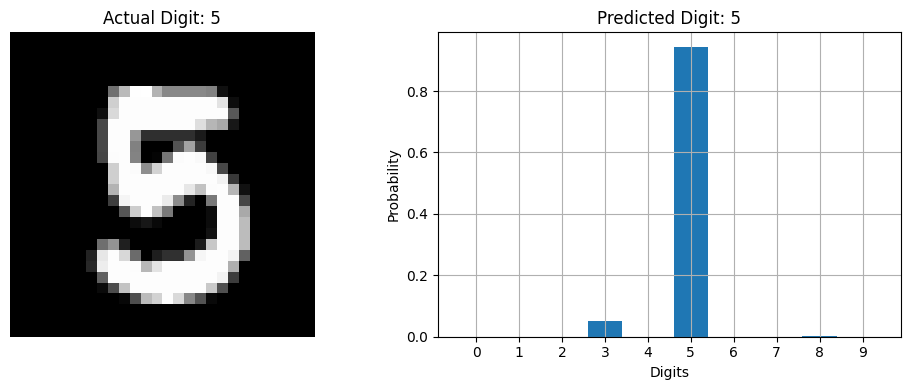


PROGRAM COMPLETED SUCCESSFULLY
1. English to Hindi Translation completed.
2. LSTM Handwriting Recognition completed.
3. Both models trained and evaluated successfully.


In [ ]:
# DLL Experiment No. 10
# LSTM Machine Translation and Handwriting Recognition

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# ==========================================
# PART 1: ENGLISH TO HINDI MACHINE TRANSLATION
# ==========================================

print("=" * 60)
print("PART 1: LSTM MACHINE TRANSLATION")
print("=" * 60)


# 1. Prepare Dataset
english_sentences = [
    "hello",
    "how are you",
    "what is your name",
    "i am fine",
    "good morning",
    "good night",
    "thank you",
    "welcome",
    "where are you going",
    "i love india",
    "this is a book",
    "i am a student",
    "she is my friend",
    "he is a doctor",
    "open the door",
    "close the door"
]

hindi_sentences = [
    "नमस्ते",
    "आप कैसे हैं",
    "आपका नाम क्या है",
    "मैं ठीक हूँ",
    "सुप्रभात",
    "शुभ रात्रि",
    "धन्यवाद",
    "स्वागत है",
    "आप कहाँ जा रहे हैं",
    "मुझे भारत से प्यार है",
    "यह एक किताब है",
    "मैं एक विद्यार्थी हूँ",
    "वह मेरी दोस्त है",
    "वह एक डॉक्टर है",
    "दरवाजा खोलो",
    "दरवाजा बंद करो"
]


# Add Start and End Tokens
hindi_sentences = [
    "<start> " + sentence + " <end>"
    for sentence in hindi_sentences
]


# 2. Tokenization
english_tokenizer = Tokenizer(
    filters="",
    lower=True,
    oov_token="<unk>"
)

hindi_tokenizer = Tokenizer(
    filters="",
    lower=False,
    oov_token="<unk>"
)

english_tokenizer.fit_on_texts(english_sentences)
hindi_tokenizer.fit_on_texts(hindi_sentences)


# Convert Text into Sequences
english_sequences = english_tokenizer.texts_to_sequences(
    english_sentences
)

hindi_sequences = hindi_tokenizer.texts_to_sequences(
    hindi_sentences
)


# 3. Padding
max_encoder_length = max(
    len(x) for x in english_sequences
)

max_decoder_length = max(
    len(x) for x in hindi_sequences
)

encoder_input = pad_sequences(
    english_sequences,
    maxlen=max_encoder_length,
    padding="post"
)

decoder_full = pad_sequences(
    hindi_sequences,
    maxlen=max_decoder_length,
    padding="post"
)

decoder_input = decoder_full[:, :-1]

decoder_target = decoder_full[:, 1:]


# Vocabulary Size
english_vocab_size = len(
    english_tokenizer.word_index
) + 1

hindi_vocab_size = len(
    hindi_tokenizer.word_index
) + 1

print("English Vocabulary:", english_vocab_size)
print("Hindi Vocabulary:", hindi_vocab_size)


# 4. Define LSTM Architecture
embedding_dim = 128
lstm_units = 128


# Encoder
encoder_inputs = layers.Input(shape=(None,))

encoder_embedding = layers.Embedding(
    english_vocab_size,
    embedding_dim,
    mask_zero=True
)(encoder_inputs)

_, state_h, state_c = layers.LSTM(
    lstm_units,
    return_state=True
)(encoder_embedding)

encoder_states = [state_h, state_c]


# Decoder
decoder_inputs = layers.Input(shape=(None,))

decoder_embedding_layer = layers.Embedding(
    hindi_vocab_size,
    embedding_dim,
    mask_zero=True
)

decoder_embedding = decoder_embedding_layer(
    decoder_inputs
)

decoder_lstm = layers.LSTM(
    lstm_units,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=encoder_states
)

decoder_dense = layers.Dense(
    hindi_vocab_size,
    activation="softmax"
)

decoder_outputs = decoder_dense(decoder_outputs)


# 5. Create Translation Model
translation_model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)


# Compile Model
translation_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# 6. Train Translation Model
print("\nTraining LSTM Translation Model...")

sample_weights = (decoder_target != 0).astype("float32")

translation_model.fit(
    [encoder_input, decoder_input],
    np.expand_dims(decoder_target, -1),
    sample_weight=sample_weights,
    batch_size=4,
    epochs=300,
    verbose=0
)

print("Translation Model Trained Successfully!")


# 7. Create Encoder Inference Model
encoder_model = Model(
    encoder_inputs,
    encoder_states
)


# Create Decoder Inference Model
decoder_state_input_h = layers.Input(
    shape=(lstm_units,)
)

decoder_state_input_c = layers.Input(
    shape=(lstm_units,)
)

decoder_states_inputs = [
    decoder_state_input_h,
    decoder_state_input_c
]

decoder_embedding_inf = decoder_embedding_layer(
    decoder_inputs
)

decoder_outputs_inf, state_h_inf, state_c_inf = decoder_lstm(
    decoder_embedding_inf,
    initial_state=decoder_states_inputs
)

decoder_outputs_inf = decoder_dense(
    decoder_outputs_inf
)

decoder_model = Model(
    [decoder_inputs] + decoder_states_inputs,
    [decoder_outputs_inf, state_h_inf, state_c_inf]
)


# 8. Translation Function
reverse_hindi_index = {
    value: key
    for key, value in hindi_tokenizer.word_index.items()
}


def translate(sentence):

    sentence = sentence.lower().strip()

    sequence = english_tokenizer.texts_to_sequences(
        [sentence]
    )

    if not sequence[0]:
        return "Sentence not available in vocabulary."

    sequence = pad_sequences(
        sequence,
        maxlen=max_encoder_length,
        padding="post"
    )

    states = encoder_model.predict(
        sequence,
        verbose=0
    )

    start_token = hindi_tokenizer.word_index["<start>"]

    end_token = hindi_tokenizer.word_index["<end>"]

    target_sequence = np.array([[start_token]])

    translated_words = []

    for _ in range(max_decoder_length):

        output_tokens, h, c = decoder_model.predict(
            [target_sequence] + states,
            verbose=0
        )

        sampled_token_index = int(
            np.argmax(output_tokens[0, -1, :])
        )

        sampled_word = reverse_hindi_index.get(
            sampled_token_index,
            ""
        )

        if sampled_token_index == end_token:
            break

        if sampled_word not in ["<start>", "<end>", "<unk>", ""]:
            translated_words.append(sampled_word)

        target_sequence = np.array(
            [[sampled_token_index]]
        )

        states = [h, c]

    return " ".join(translated_words)


# 9. Test Translation
sample_index = np.random.randint(
    0, len(english_sentences)
)

user_sentence = english_sentences[sample_index]

print("\nEnglish Sentence:", user_sentence)

print("Hindi Translation:", translate(user_sentence))


# ==========================================
# PART 2: LSTM HANDWRITING RECOGNITION
# ==========================================

print("\n" + "=" * 60)
print("PART 2: LSTM HANDWRITING RECOGNITION")
print("=" * 60)


# 10. Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("MNIST Dataset Loaded Successfully!")

print("Training Images:", x_train.shape)

print("Testing Images:", x_test.shape)


# 11. Normalize Images
x_train = x_train.astype("float32") / 255.0

x_test = x_test.astype("float32") / 255.0

# Each image is treated as a sequence of 28 rows.
# 28 time steps, 28 features per time step.


# 12. Build LSTM Model
handwriting_model = Sequential([

    layers.Input(shape=(28, 28)),

    layers.LSTM(
        128,
        activation="tanh"
    ),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        10,
        activation="softmax"
    )

], name="LSTM_Handwriting_Recognition")


# 13. Compile Model
handwriting_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


print("\nHandwriting Recognition Model:")
handwriting_model.summary()


# 14. Train Model
print("\nTraining LSTM Handwriting Model...")

history = handwriting_model.fit(
    x_train,
    y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=128,
    verbose=1
)

print("\nHandwriting Model Trained Successfully!")


# 15. Evaluate Model
test_loss, test_accuracy = handwriting_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("\nTest Accuracy:", round(test_accuracy * 100, 2), "%")

print("Test Loss:", round(test_loss, 4))


# 16. Predict Random Handwritten Digit
sample_index = np.random.randint(
    0, len(x_test)
)

test_image = x_test[sample_index]

actual_digit = y_test[sample_index]

prediction = handwriting_model.predict(
    np.expand_dims(test_image, axis=0),
    verbose=0
)[0]

predicted_digit = int(np.argmax(prediction))

confidence = float(np.max(prediction))


# 17. Display Prediction
print("\n" + "-" * 60)

print("HANDWRITING RECOGNITION RESULT")

print("-" * 60)

print("Actual Digit:", actual_digit)

print("Predicted Digit:", predicted_digit)

print("Confidence:", round(confidence * 100, 2), "%")


# Display Softmax Probabilities
print("\nDigit Probabilities:")

for i, probability in enumerate(prediction):

    print(
        "Digit", i,
        ":", round(float(probability * 100), 2), "%"
    )


# 18. Display Image and Prediction
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)

plt.imshow(test_image, cmap="gray")

plt.title(
    "Actual Digit: " + str(actual_digit)
)

plt.axis("off")


plt.subplot(1, 2, 2)

plt.bar(
    range(10),
    prediction
)

plt.title(
    "Predicted Digit: " + str(predicted_digit)
)

plt.xlabel("Digits")

plt.ylabel("Probability")

plt.xticks(range(10))

plt.grid(True)

plt.tight_layout()

plt.show()


# 19. Final Result
print("\n" + "=" * 60)

print("PROGRAM COMPLETED SUCCESSFULLY")

print("=" * 60)

print("1. English to Hindi Translation completed.")

print("2. LSTM Handwriting Recognition completed.")

print("3. Both models trained and evaluated successfully.")

print("=" * 60)